# Paso 3 — IRT: Teoría de Respuesta al Ítem

**Input:** `dataset_efa_items_seleccionados.csv` (235 ítems, 6,968 estudiantes)  
**Output:** `dataset_irt_items_finales.csv` — ítems que superan los criterios de discriminación  

**Modelos aplicados:**
- **2PL** (Two-Parameter Logistic) → ítems dicotómicos (2 valores únicos)
- **GRM** (Graded Response Model) → ítems politómicos (3–10 valores únicos)

**Criterio de retención:** discriminación `a >= 0.5` en ambos modelos  
Ítems con `a < 0.5` no diferencian bien entre estudiantes de distinto nivel y se descartan.

## 0. Librerías

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings("ignore")

from girth import twopl_mml, grm_mml

# Umbral de discriminación para retener un ítem
UMBRAL_DISCRIMINACION = 0.5

print("Librerías cargadas.")

Librerías cargadas.


## 1. Cargar dataset

In [35]:
df = pd.read_csv("/workspace/data/output_rural/dataset_efa_items_seleccionados.csv", low_memory=False)
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")

# Separar dicotómicas y politómicas
unicos = df.nunique()
cols_dico = unicos[unicos == 2].index.tolist()
cols_poli = unicos[unicos >  2].index.tolist()

print(f"\nÍtems dicotómicos (2PL) : {len(cols_dico)}")
print(f"Ítems politómicos (GRM) : {len(cols_poli)}")

Dataset cargado: 3,720 filas × 198 columnas

Ítems dicotómicos (2PL) : 38
Ítems politómicos (GRM) : 160


## 2. Preprocesamiento

- Imputar missing con la moda por columna
- Recodificar dicotómicas a 0/1
- Recodificar politómicas a enteros consecutivos desde 0

In [36]:
def imputar_moda(serie):
    moda = serie.mode()
    if len(moda) == 0:
        return serie.fillna(0)
    return serie.fillna(moda.iloc[0])

def recodificar_consecutivo(serie):
    """Convierte valores únicos a enteros 0, 1, 2, ... en orden ascendente."""
    vals = sorted(serie.dropna().unique())
    mapa = {v: i for i, v in enumerate(vals)}
    return serie.map(mapa)

# Dicotómicas → 0/1
df_dico = df[cols_dico].apply(imputar_moda)
df_dico = df_dico.apply(recodificar_consecutivo)
df_dico = df_dico.astype(int)

# Politómicas → 0, 1, 2, ...
df_poli = df[cols_poli].apply(imputar_moda)
df_poli = df_poli.apply(recodificar_consecutivo)
df_poli = df_poli.astype(int)

print("Preprocesamiento completado.")
print(f"  Dicotómicas — valores únicos por columna: {df_dico.apply(pd.Series.nunique).value_counts().to_dict()}")
print(f"  Politómicas — rango de valores únicos   : {df_poli.apply(pd.Series.nunique).min()} – {df_poli.apply(pd.Series.nunique).max()}")

Preprocesamiento completado.
  Dicotómicas — valores únicos por columna: {2: 38}
  Politómicas — rango de valores únicos   : 3 – 10


## 3. Modelo 2PL — ítems dicotómicos

In [37]:
print("Ajustando modelo 2PL...")

# girth espera matriz de ítems × personas (transpuesta)
datos_dico = df_dico.values.T

try:
    resultado_2pl = twopl_mml(datos_dico)
    discriminacion_2pl = resultado_2pl["Discrimination"]   # parámetro a
    dificultad_2pl     = resultado_2pl["Difficulty"]        # parámetro b

    df_params_dico = pd.DataFrame({
        "item"            : cols_dico,
        "modelo"          : "2PL",
        "discriminacion"  : discriminacion_2pl,
        "dificultad"      : dificultad_2pl,
        "n_categorias"    : 2,
    })

    print(f"2PL ajustado correctamente.")
    print(f"  Discriminación — media : {discriminacion_2pl.mean():.3f}")
    print(f"  Discriminación — rango : {discriminacion_2pl.min():.3f} – {discriminacion_2pl.max():.3f}")
    print(f"  Dificultad     — media : {dificultad_2pl.mean():.3f}")

except Exception as e:
    print(f"Error en 2PL: {e}")
    df_params_dico = pd.DataFrame(columns=["item", "modelo", "discriminacion", "dificultad", "n_categorias"])

Ajustando modelo 2PL...
2PL ajustado correctamente.
  Discriminación — media : 1.148
  Discriminación — rango : 0.200 – 5.000
  Dificultad     — media : 1.912


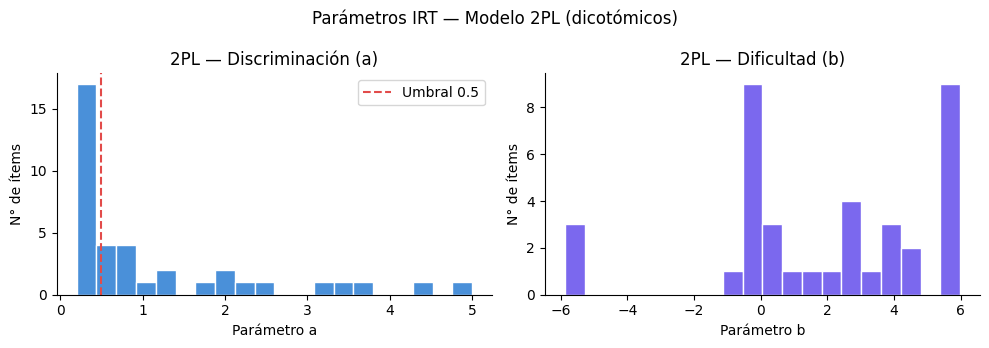

Ítems 2PL retenidos (a ≥ 0.5): 21 / 38


In [38]:
# Visualización 2PL
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(discriminacion_2pl, bins=20, color="#4A90D9", edgecolor="white")
axes[0].axvline(UMBRAL_DISCRIMINACION, color="#E24B4A", linewidth=1.5,
                linestyle="--", label=f"Umbral {UMBRAL_DISCRIMINACION}")
axes[0].set_title("2PL — Discriminación (a)")
axes[0].set_xlabel("Parámetro a")
axes[0].set_ylabel("N° de ítems")
axes[0].legend()
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].hist(dificultad_2pl, bins=20, color="#7B68EE", edgecolor="white")
axes[1].set_title("2PL — Dificultad (b)")
axes[1].set_xlabel("Parámetro b")
axes[1].set_ylabel("N° de ítems")
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Parámetros IRT — Modelo 2PL (dicotómicos)", fontsize=12)
plt.tight_layout()
plt.show()

retenidos_2pl = df_params_dico[df_params_dico["discriminacion"] >= UMBRAL_DISCRIMINACION]
print(f"Ítems 2PL retenidos (a ≥ {UMBRAL_DISCRIMINACION}): {len(retenidos_2pl)} / {len(cols_dico)}")

## 4. Modelo GRM — ítems politómicos

In [39]:
print("Ajustando modelo GRM — puede tardar unos minutos con 190 ítems...")

# girth espera matriz ítems × personas con todos los ítems a la vez
datos_poli = df_poli.values.T  # shape: (190 ítems, 6968 personas)

try:
    resultado_grm = grm_mml(datos_poli)
    discriminacion_grm   = np.array(resultado_grm["Discrimination"]).flatten()
    dificultad_raw       = resultado_grm["Difficulty"]

    # Dificultad puede ser matriz (un umbral por categoría) — tomamos la media por ítem
    if isinstance(dificultad_raw, np.ndarray) and dificultad_raw.ndim == 2:
        dificultad_grm_media = dificultad_raw.mean(axis=1)
    else:
        dificultad_grm_media = np.array(dificultad_raw).flatten()

    cols_grm_ok  = cols_poli
    errores_grm  = []

    df_params_poli = pd.DataFrame({
        "item"           : cols_grm_ok,
        "modelo"         : "GRM",
        "discriminacion" : discriminacion_grm,
        "dificultad"     : dificultad_grm_media,
        "n_categorias"   : [df_poli[c].nunique() for c in cols_grm_ok],
    })

    print(f"GRM ajustado correctamente: {len(cols_grm_ok)} ítems")
    print(f"  Discriminación — media : {discriminacion_grm.mean():.3f}")
    print(f"  Discriminación — rango : {discriminacion_grm.min():.3f} – {discriminacion_grm.max():.3f}")
    print(f"  Dificultad     — media : {dificultad_grm_media.mean():.3f}")

except Exception as e:
    print(f"Error en GRM: {e}")
    df_params_poli = pd.DataFrame(
        columns=["item", "modelo", "discriminacion", "dificultad", "n_categorias"]
    )
    cols_grm_ok = []
    errores_grm = [(col, str(e)) for col in cols_poli]

Ajustando modelo GRM — puede tardar unos minutos con 190 ítems...
GRM ajustado correctamente: 160 ítems
  Discriminación — media : 0.769
  Discriminación — rango : 0.200 – 2.978
  Dificultad     — media : nan


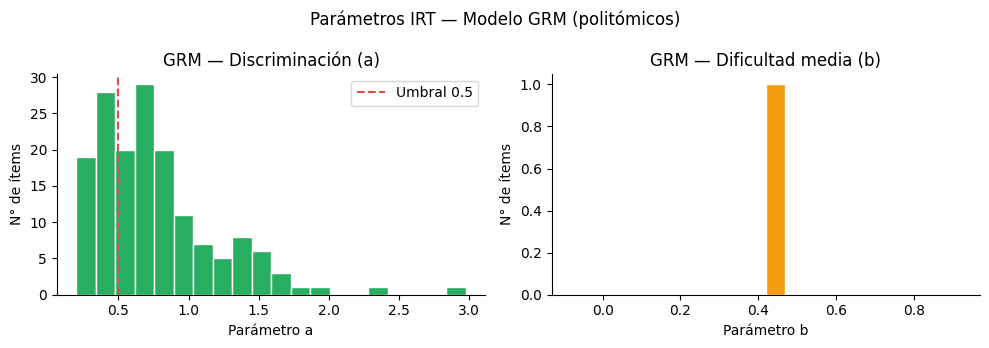

Ítems GRM retenidos (a ≥ 0.5): 108 / 160


In [40]:
# Visualización GRM
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(discriminacion_grm, bins=20, color="#27AE60", edgecolor="white")
axes[0].axvline(UMBRAL_DISCRIMINACION, color="#E24B4A", linewidth=1.5,
                linestyle="--", label=f"Umbral {UMBRAL_DISCRIMINACION}")
axes[0].set_title("GRM — Discriminación (a)")
axes[0].set_xlabel("Parámetro a")
axes[0].set_ylabel("N° de ítems")
axes[0].legend()
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].hist(dificultad_grm_media, bins=20, color="#F39C12", edgecolor="white")
axes[1].set_title("GRM — Dificultad media (b)")
axes[1].set_xlabel("Parámetro b")
axes[1].set_ylabel("N° de ítems")
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Parámetros IRT — Modelo GRM (politómicos)", fontsize=12)
plt.tight_layout()
plt.show()

retenidos_grm = df_params_poli[df_params_poli["discriminacion"] >= UMBRAL_DISCRIMINACION]
print(f"Ítems GRM retenidos (a ≥ {UMBRAL_DISCRIMINACION}): {len(retenidos_grm)} / {len(cols_grm_ok)}")

## 5. Curvas características — los 6 mejores ítems de cada modelo

Las curvas características (ICC) muestran cómo cambia la probabilidad de respuesta correcta según el nivel del estudiante (θ).  
Un ítem ideal tiene curva en S pronunciada — discrimina bien entre niveles bajos y altos.

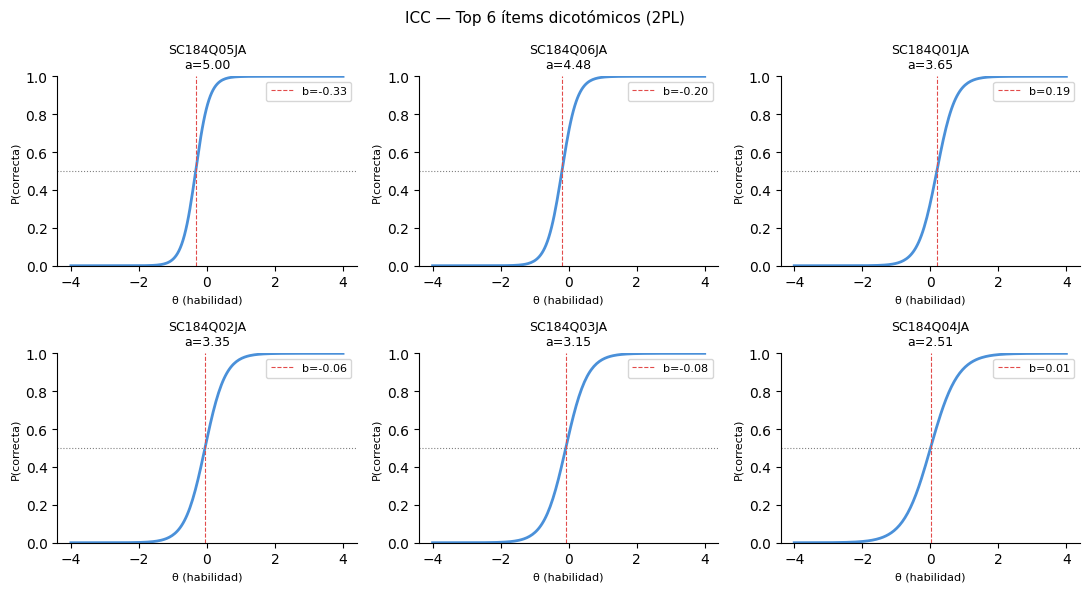

In [41]:
from scipy.special import expit  # función logística

theta = np.linspace(-4, 4, 200)

# Top 6 ítems 2PL por discriminación
top_2pl = df_params_dico.nlargest(6, "discriminacion")

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
axes = axes.flatten()

for i, (_, fila) in enumerate(top_2pl.iterrows()):
    a, b = fila["discriminacion"], fila["dificultad"]
    prob = expit(a * (theta - b))
    axes[i].plot(theta, prob, color="#4A90D9", linewidth=2)
    axes[i].axhline(0.5, color="gray", linewidth=0.8, linestyle=":")
    axes[i].axvline(b,   color="#E24B4A", linewidth=0.8, linestyle="--", label=f"b={b:.2f}")
    axes[i].set_title(f"{fila['item']}\na={a:.2f}", fontsize=9)
    axes[i].set_xlabel("θ (habilidad)", fontsize=8)
    axes[i].set_ylabel("P(correcta)", fontsize=8)
    axes[i].set_ylim(0, 1)
    axes[i].legend(fontsize=8)
    axes[i].spines[["top", "right"]].set_visible(False)

plt.suptitle("ICC — Top 6 ítems dicotómicos (2PL)", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Resumen consolidado y selección final

In [42]:
# Consolidar parámetros de ambos modelos
df_params_total = pd.concat([df_params_dico, df_params_poli], ignore_index=True)

# Ítems retenidos
df_retenidos = df_params_total[df_params_total["discriminacion"] >= UMBRAL_DISCRIMINACION].copy()
items_finales = df_retenidos["item"].tolist()

print("═" * 55)
print(f"  {'Modelo':<12} {'Total':>8} {'Retenidos':>12} {'Descartados':>12}")
print("═" * 55)
for modelo in ["2PL", "GRM"]:
    sub = df_params_total[df_params_total["modelo"] == modelo]
    ret = df_retenidos[df_retenidos["modelo"] == modelo]
    print(f"  {modelo:<12} {len(sub):>8} {len(ret):>12} {len(sub)-len(ret):>12}")
print("─" * 55)
print(f"  {'TOTAL':<12} {len(df_params_total):>8} {len(items_finales):>12} {len(df_params_total)-len(items_finales):>12}")
print("═" * 55)

# Estadísticas de discriminación de los retenidos
print(f"\nDiscriminación de ítems retenidos:")
print(f"  Media  : {df_retenidos['discriminacion'].mean():.3f}")
print(f"  Mínimo : {df_retenidos['discriminacion'].min():.3f}")
print(f"  Máximo : {df_retenidos['discriminacion'].max():.3f}")

═══════════════════════════════════════════════════════
  Modelo          Total    Retenidos  Descartados
═══════════════════════════════════════════════════════
  2PL                38           21           17
  GRM               160          108           52
───────────────────────────────────────────────────────
  TOTAL             198          129           69
═══════════════════════════════════════════════════════

Discriminación de ítems retenidos:
  Media  : 1.109
  Mínimo : 0.503
  Máximo : 5.000


## 7. Guardar outputs

In [44]:
# Dataset final con solo los ítems que pasaron el IRT
df_final = df[items_finales].copy()
df_final.to_csv("/workspace/data/output_rural/dataset_irt_items_finales.csv", index=False)
print(f"Guardado: dataset_irt_items_finales.csv")
print(f"  Filas : {df_final.shape[0]:,}")
print(f"  Ítems : {df_final.shape[1]:,}")

# Tabla completa de parámetros IRT — útil para el artículo
df_params_total.sort_values("discriminacion", ascending=False).to_csv(
    "/workspace/data/output_rural/irt_parametros_todos.csv", index=False
)
print("Guardado: irt_parametros_todos.csv")

# Solo los retenidos
df_retenidos.sort_values("discriminacion", ascending=False).to_csv(
    "/workspace/data/output_rural/irt_parametros_retenidos.csv", index=False
)
print("Guardado: irt_parametros_retenidos.csv")

print(f"\nSiguiente paso → paso4_lca.ipynb")

Guardado: dataset_irt_items_finales.csv
  Filas : 3,720
  Ítems : 129
Guardado: irt_parametros_todos.csv
Guardado: irt_parametros_retenidos.csv

Siguiente paso → paso4_lca.ipynb


## 8. ── OPCIONAL ── Ajustar umbral de discriminación

Si el número de ítems retenidos es demasiado alto (>120) o demasiado bajo (<30),
puedes ajustar el umbral y re-ejecutar solo las celdas 6 y 7.

| Umbral | Criterio                          |
|--------|-----------------------------------|
| 0.35   | Conservador — retiene más ítems   |
| 0.50   | Estándar recomendado              |
| 0.70   | Estricto — solo los mejores       |

In [ ]:
# Descomenta para probar otro umbral sin re-ejecutar los modelos
# UMBRAL_DISCRIMINACION = 0.35
# df_retenidos = df_params_total[df_params_total["discriminacion"] >= UMBRAL_DISCRIMINACION].copy()
# items_finales = df_retenidos["item"].tolist()
# print(f"Con umbral {UMBRAL_DISCRIMINACION}: {len(items_finales)} ítems retenidos")